<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Test Accuracy: 86.00%


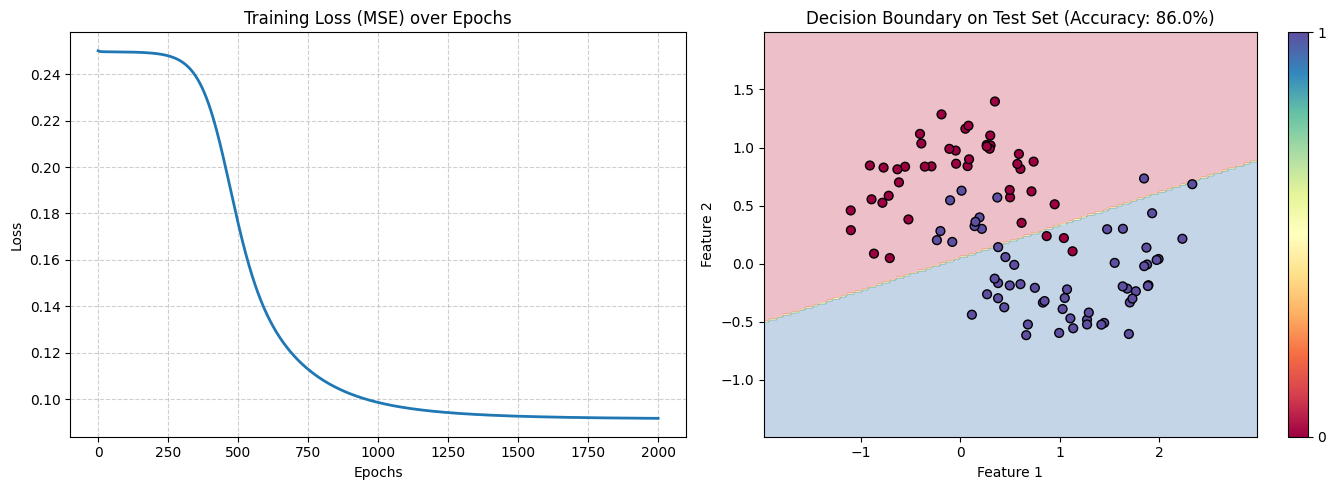

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# 1. Define the Neural Network from Scratch
class NeuralNetwork:
    def __init__(self, input_dim, hidden_dim, output_dim, learning_rate=0.1):
        self.lr = learning_rate
        # Initialize weights and biases
        self.W1 = np.random.randn(input_dim, hidden_dim) * 0.01
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * 0.01
        self.b2 = np.zeros((1, output_dim))
        self.loss_history = []

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def sigmoid_derivative(self, x):
        return x * (1 - x)

    def forward(self, X):
        # Forward propagation
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = self.sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = self.sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output):
        # Backpropagation algorithm
        m = X.shape[0]

        # Error at output layer
        error_output = output - y
        d_output = error_output * self.sigmoid_derivative(output)

        # Error at hidden layer
        error_hidden = np.dot(d_output, self.W2.T)
        d_hidden = error_hidden * self.sigmoid_derivative(self.a1)

        # Gradients
        dW2 = np.dot(self.a1.T, d_output) / m
        db2 = np.sum(d_output, axis=0, keepdims=True) / m
        dW1 = np.dot(X.T, d_hidden) / m
        db1 = np.sum(d_hidden, axis=0, keepdims=True) / m

        # Update weights and biases
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

    def train(self, X, y, epochs=1000):
        for epoch in range(epochs):
            output = self.forward(X)
            self.backward(X, y, output)
            loss = np.mean(np.square(y - output))  # Mean Squared Error
            self.loss_history.append(loss)

    def predict(self, X):
        return (self.forward(X) > 0.5).astype(int)

# 2. Generate Dataset
X, y = make_moons(n_samples=500, noise=0.2, random_state=42)
y = y.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Train the Network
nn = NeuralNetwork(input_dim=2, hidden_dim=8, output_dim=1, learning_rate=0.5)
nn.train(X_train, y_train, epochs=2000)

# 4. Evaluate and Visualize Results
predictions = nn.predict(X_test)
accuracy = np.mean(predictions == y_test) * 100
print(f"Test Accuracy: {accuracy:.2f}%")

# Plotting Decision Boundary and Loss Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss Curve
ax1.plot(nn.loss_history, color='#1f77b4', lw=2)
ax1.set_title("Training Loss (MSE) over Epochs")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot Decision Boundary
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = nn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

ax2.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Spectral)
scatter = ax2.scatter(X_test[:, 0], X_test[:, 1], c=y_test.ravel(), cmap=plt.cm.Spectral, edgecolors='k', s=40)
ax2.set_title(f"Decision Boundary on Test Set (Accuracy: {accuracy:.1f}%)")
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")
fig.colorbar(scatter, ax=ax2, ticks=[0, 1])

plt.tight_layout()
plt.show()